# Single-allele domains with FISHnet

TAD callers on tracing data usually pool all traces into one answer per
chromosome.  FISHnet (Patel et al. 2025, *Nature Methods* 22:1255,
doi:10.1038/s41592-025-02688-1) calls domains on **each allele
separately**, so cell-to-cell variability becomes visible.  This tutorial
runs `uchrom.strc.tad.call_domains_fishnet_trace` on one allele and
`call_domains_fishnet` (also `uc.tl.call_tads(method="fishnet")`) on a
sample of alleles, sums them into the ensemble domain mask, and compares
the single-allele boundaries with the population boundaries of the ArcFISH
caller (`call_tads_by_pval`) with `boundary_frequency` and
`tad_boundaries`.  Data: Takei et al. 2021 (*Nature* 590:344) mESC DNA
seqFISH+ at 25 kb, the 60-locus (1.5-Mb) region on chr6, as a `ChromData`
from `ds.load("takei2021_mesc")` (the first call downloads the FOF-CT core
table `4DNFIHF3JCBY`, 22 MB, and its cell and RNA tables once from 4DN).
Runtime: 2–5 minutes (FISHnet runs Louvain many times per allele on the CPU).

**How FISHnet works** (per allele):

1. **Threshold sweep** — binarise the allele's pairwise distance matrix at
   a series of distance thresholds (`(i, j) → 1` if `dist ≤ t`).
2. **Smooth** — a `(2w)×(2w)` boxcar turns the binary map into a weighted
   graph.
3. **Louvain modularity** — run Louvain community detection several times
   per threshold and keep the consensus partition (highest mean adjusted
   Rand index to the other runs).
4. **Plateaus** — runs of `plateau_size` or more consecutive thresholds
   with the same number of communities; each plateau gives one partition.
5. **Clean-up** — merge runs shorter than `size_exclusion` loci and
   boundaries closer than `merge_tol` loci.

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import uchrom as uc
import uchrom.datasets as ds

plt.rcParams["figure.dpi"] = 90

OUT = Path("_out"); OUT.mkdir(exist_ok=True)   # outputs: tutorials/_out/ (ignored by git)

## Load the traces and pick a chromosome

In [2]:
from uchrom.strc.tad import (FISHnetParams, TADCallerParams, call_domains_fishnet,
                             call_domains_fishnet_trace, call_tads_by_pval)

cd = ds.load("takei2021_mesc")
CHROM = "chr6"
n_loci = int((cd.bins["chrom"] == CHROM).sum())
coverage = cd.get_chrom(CHROM).spots.groupby("trace_id", observed=True)["bin_id"].nunique() / n_loci
print(f"{CHROM}: {n_loci} loci, {len(coverage)} alleles; "
      f"median coverage {coverage.median():.0%}, {int((coverage >= 0.6).sum())} alleles with ≥ 60 %")

chr6: 60 loci, 415 alleles; median coverage 55%, 179 alleles with ≥ 60 %


## One allele

`call_domains_fishnet_trace` works on one allele: a pairwise distance
matrix (NaN for undetected loci, which are linearly imputed when
`impute=True`), or a trace of the `ChromData` — with `trace_id=` it builds
that matrix over every locus of the trace's chromosome and returns it with
the domains.  Run FISHnet with the paper's defaults on the best-covered
allele.  Its Louvain runs are seeded by the allele's id
(`uchrom.strc.tad.trace_seed`), the same seed `call_domains_fishnet` gives
it below.

In [3]:
demo = str(coverage.idxmax())
t0 = time.perf_counter()
res = call_domains_fishnet_trace(cd, trace_id=demo, params=FISHnetParams())      # paper defaults
D = res["distances"]                                                             # µm, n_loci × n_loci
print(f"allele {demo} (coverage {coverage.max():.0%}): {len(res['domains'])} domains from "
      f"{res['n_plateaus']} plateaus, boundaries at loci {res['boundaries']} "
      f"({time.perf_counter() - t0:.1f} s)")

allele 4_12_6_1 (coverage 98%): 6 domains from 4 plateaus, boundaries at loci [4, 8, 21, 40, 47] (65.4 s)


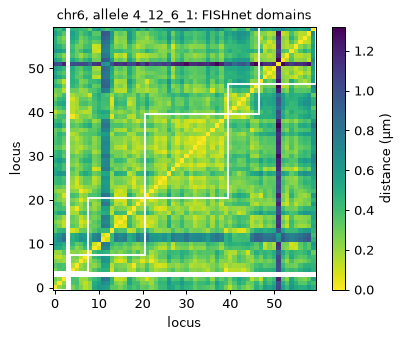

In [4]:
from uchrom.pl import draw_domains

fig, ax = plt.subplots(figsize=(4.6, 3.8))
im = ax.imshow(D, cmap="viridis_r", origin="lower")
draw_domains(ax, res["domains"], edgecolor="white", lw=1.5)                      # row ranges of D
ax.set_title(f"{CHROM}, allele {demo}: FISHnet domains", fontsize=10)
ax.set_xlabel("locus"); ax.set_ylabel("locus")
plt.colorbar(im, ax=ax, label="distance (µm)")
plt.tight_layout(); plt.show()

## Many alleles → ensemble domain mask

`call_domains_fishnet` runs every selected allele of a chromosome.  We pick
40 random alleles with at least 60 % of the loci detected (`trace_ids=`)
and lighten the sweep (10 Louvain runs at each of 30 thresholds, plateaus
of 3) to keep the runtime down.  The per-allele domains are stored as a
`domain` interval table under `"tads.fishnet"`; the ensemble domain mask —
for each locus pair, how often (alleles × plateaus) both loci share a
domain — under `"tads.fishnet.ensemble"`.

In [5]:
rng = np.random.default_rng(0)
eligible = coverage[coverage >= 0.6].index.astype(str)
sample = rng.choice(eligible, size=40, replace=False)
FAST = FISHnetParams(n_louvain_runs=10, max_thresholds=30, plateau_size=3)

t0 = time.perf_counter()
fn = call_domains_fishnet(cd, chrom=CHROM, trace_ids=sample, params=FAST)
n_called = fn.trace_id.nunique()
print(f"{len(fn)} domains on {n_called} of {len(sample)} alleles ({time.perf_counter() - t0:.0f} s)")
print(cd.intervals)
fn.head()

223 domains on 40 of 40 alleles (136 s)
IntervalStore({'tads.fishnet': <domain, 223 rows>})


,chrom,trace_id,domain_idx,start,end,start_bin,end_bin
0,chr6,0_10_6_1,0,49375000,49550000,0,6
1,chr6,0_10_6_1,1,49550000,49700000,6,12
2,chr6,0_10_6_1,2,49700000,49950000,12,22
3,chr6,0_10_6_1,3,49950000,50250000,22,34
4,chr6,0_10_6_1,4,50250000,50350000,34,38


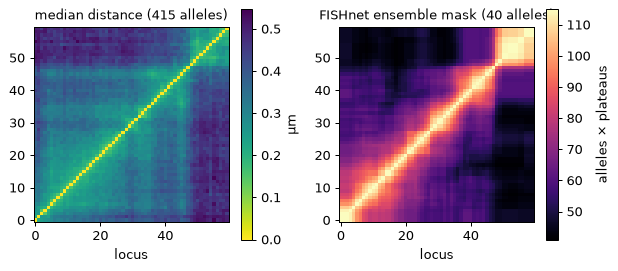

In [6]:
from uchrom.fea import distance_map

ens = cd.results["tads.fishnet.ensemble"][CHROM]       # one entry per chromosome
dm = distance_map(cd, CHROM)                            # all alleles, median

fig, axes = plt.subplots(1, 2, figsize=(7, 3.1))
im0 = axes[0].imshow(dm.matrix, cmap="viridis_r", origin="lower")
axes[0].set_title(f"median distance ({dm.n_traces} alleles)", fontsize=10)
plt.colorbar(im0, ax=axes[0], label="µm")
im1 = axes[1].imshow(ens["mask"], cmap="magma", origin="lower")
axes[1].set_title(f"FISHnet ensemble mask ({ens['n_traces']} alleles)", fontsize=10)
plt.colorbar(im1, ax=axes[1], label="alleles × plateaus")
for ax in axes:
    ax.set_xlabel("locus")
plt.tight_layout(); plt.show()

The block structure of the ensemble mask follows the low-distance blocks of
the population map: the population pattern is the sum of domains that
individual alleles form, each at somewhat different places.

## Cell-to-cell variability

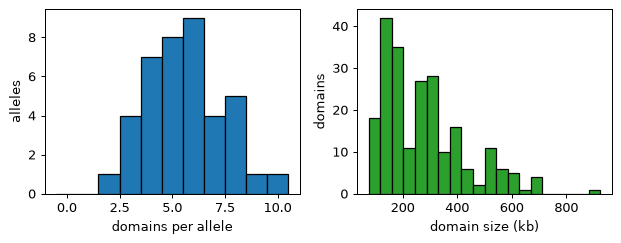

domains per allele: median 6 (range 2–10); domain size: median 250 kb


In [7]:
per_allele = fn.groupby("trace_id", observed=True).size()
size_kb = (fn.end - fn.start) / 1e3
fig, axes = plt.subplots(1, 2, figsize=(7, 2.8))
axes[0].hist(per_allele, bins=np.arange(per_allele.max() + 2) - 0.5, color="tab:blue", edgecolor="k")
axes[0].set_xlabel("domains per allele"); axes[0].set_ylabel("alleles")
axes[1].hist(size_kb, bins=20, color="tab:green", edgecolor="k")
axes[1].set_xlabel("domain size (kb)"); axes[1].set_ylabel("domains")
plt.tight_layout(); plt.show()
print(f"domains per allele: median {per_allele.median():.0f} (range {per_allele.min()}–{per_allele.max()}); "
      f"domain size: median {size_kb.median():.0f} kb")

## Single-allele boundaries vs population boundaries

The ArcFISH preprint finds that population boundaries with larger test
statistics occur more often in single cells (Pearson r = 0.45 with FISHnet
on these data).  A simple version of that check: how often is each locus
a FISHnet boundary across the alleles (`boundary_frequency`), and is that
frequency higher at the boundaries the population caller (ArcFISH window
±100 kb) finds (`tad_boundaries`)?

5 population boundaries; FISHnet boundary frequency 0.113 within ±1 locus of them vs 0.064 elsewhere (1.8×)


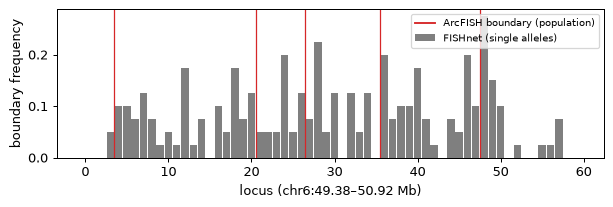

In [8]:
from uchrom.strc.tad import boundary_frequency, tad_boundaries

freq = boundary_frequency(cd, fn)                    # per locus: fraction of the alleles with a boundary there
pop = call_tads_by_pval(cd, chrom=CHROM, params=TADCallerParams(window_bp=1e5, hierarchical=False),   # ±100 kb, ArcFISH's default
                        key_added=None)
pop_idx = tad_boundaries(cd, pop)["bin_index"].to_numpy()
locus, f = freq["bin_index"].to_numpy(), freq["frequency"].to_numpy()
near = np.abs(locus[:, None] - pop_idx[None, :]).min(axis=1) <= 1                # boundary locus ± 1
print(f"{len(pop_idx)} population boundaries; FISHnet boundary frequency "
      f"{f[near].mean():.3f} within ±1 locus of them vs {f[~near].mean():.3f} elsewhere "
      f"({f[near].mean() / f[~near].mean():.1f}×)")

fig, ax = plt.subplots(figsize=(7, 2.4))
ax.bar(locus, f, color="tab:grey", width=0.9, label="FISHnet (single alleles)")
for k in pop_idx:
    ax.axvline(k - 0.5, color="tab:red", lw=1)
ax.plot([], [], color="tab:red", label="ArcFISH boundary (population)")
ax.set_xlabel(f"locus ({CHROM}:{freq.start.iloc[0] / 1e6:.2f}–{freq.end.iloc[-1] / 1e6:.2f} Mb)")
ax.set_ylabel("boundary frequency"); ax.legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()

## Notes: which caller when

- **FISHnet** (this tutorial) — per-allele domains; questions such as
  *which alleles fold alike?* or *how variable are boundaries?*
- **ArcFISH p-value caller** (`tad_calling`) — population boundaries with
  FDR control and a hierarchy.
- **Directionality index** (`call_tads_di`, `tad_calling`) — Hi-C contact
  matrices.

| Parameter | Effect |
|-----------|--------|
| `plateau_size` | larger → fewer, more stable partitions (paper: 4) |
| `window_size` | boxcar half-width in loci (paper: 2) |
| `max_thresholds` / `threshold_step` | density of the sweep; runtime grows linearly |
| `n_louvain_runs` | stability of the consensus (paper: 20); runtime grows linearly |
| `min_coverage` | skip alleles with fewer detected loci (default 60 %) |
| `impute` | interpolate undetected loci before thresholding |

The upstream implementation (`github.com/RohanpatelUpenn/FISHnet`, no
open-source licence) uses its own Louvain solver; this independent
re-implementation uses `networkx.algorithms.community.louvain_communities`,
so it is slow: several seconds per allele with the light settings above.
Alleles are independent — split `trace_ids` across processes for whole data
sets.

## Next steps

- `tad_calling` — population TADs, hierarchy, streaming on backed stores.
- `loop_calling` — loops on the same data.